<p align="center">
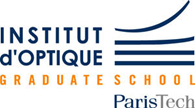&nbsp;&nbsp;&nbsp;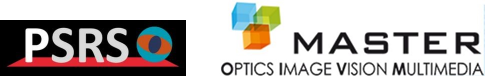
</p>

# Digital Holography : numerical simulation and reconstruction¶
## Lab 3 - Fresnel Transform to simulate free space propagation
### Lab proposed by Corinne Fournier, Felix Riedel, Thomas Olivier, Dylan Brault
### Report written by : CHUKWUJAMA Osinachi


***


It is mandatory to annotate/comment your scripts. The lab report will be uploaded on Moodle at the end of each session and a completed report would be uploaded before the next session. It will contain the programs/functions and the images results as well as your comments. It should be personal.

++++ questions are optional.

***


In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import scipy as sp

plt.rcParams["figure.figsize"] = (12,8)

## 1. Fresnel function and sampling

In [5]:
def FresnelFunction(H,W,z,wavelength,pp):
    # This function computes the Fresnel Kernel
    # Input parameters:
    #     - H,W: Number of rows and columns of the Fresnel kernel
    #     - z: Propagation distance in meters
    #     - wavelength: wavelength in meters
    #     - pp: pixel pitch in meters
    # Output parameter:
    #     - hz: matrix of H rows and W columns of complex values of the Fresnel kernel

    hz=np.zeros([H,W]);

    # for images with an even number of columns and rows, the geometrical center is W/2+1,H/2+1
    # for images with an odd number of columns and rows, the geometrical center is np.ceil(W/2),np.ceil(H/2)
    xi=np.arange(-np.floor(W/2), np.floor(W/2))
    et=np.arange(-np.floor(H/2), np.floor(H/2))

    [Xi,Et]=np.meshgrid(xi,et)

    Xi=Xi*pp
    Et=Et*pp

    c1=1/wavelength/z/1j
    c2=1j*np.pi/wavelength/z
    exp1 = 1j * 2 * np.pi * z/wavelength

    hz=np.exp(exp1)*c1*np.exp(c2*(Xi**2+Et**2))
    # the phase term exp(1j*2*np.pi*z/wavelength) will have no effect in intensity computation

    return hz

In [3]:
wavelength=0.532e-6
pp=10e-6
W=256
H=256

### 1.1.	Using the program, display the Fresnel functions computed for various distances $z=50 \ mm$, $z=30 \ mm$, $z=20 \ mm$. Comment.

In [7]:
x=np.arange(-np.floor(W/2),np.floor(W/2))
y=np.arange(-np.floor(H/2),np.floor(H/2))
x=x*pp
y=y*pp

Z=np.array([0.05, 0.03,0.02])


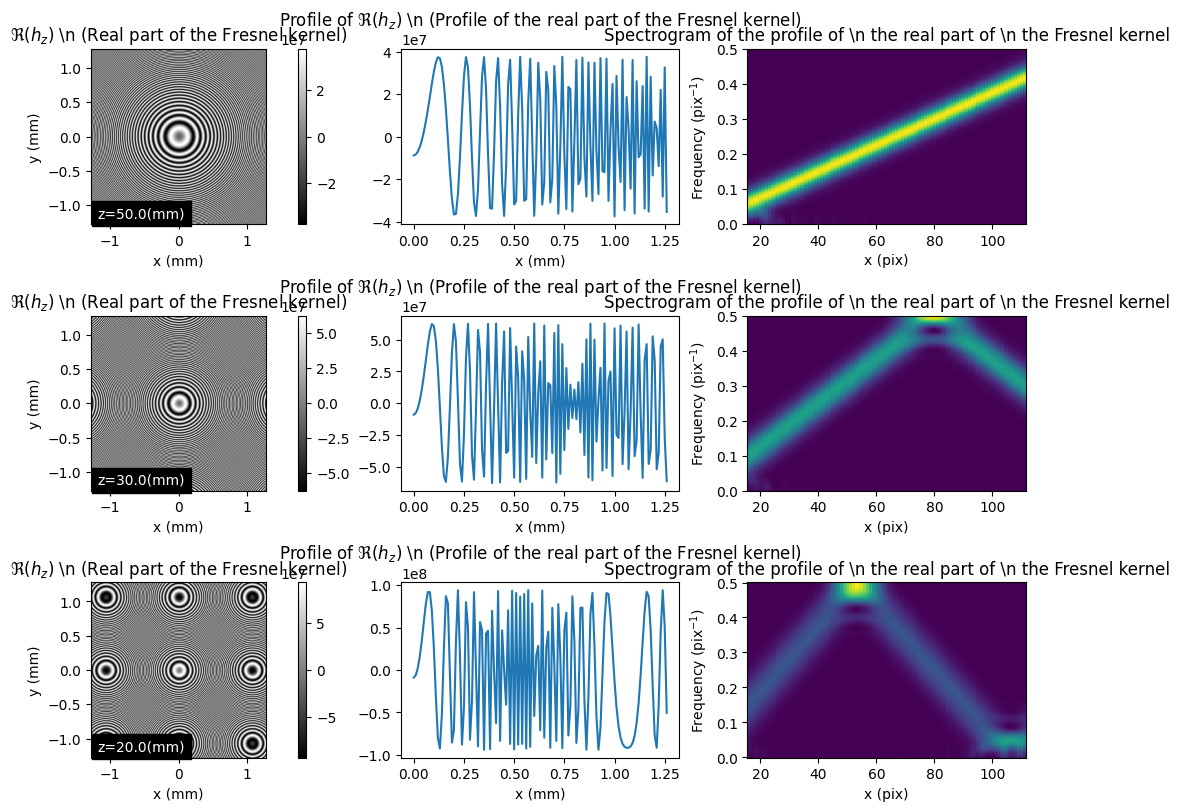

In [12]:
plt.figure(layout="compressed")
l = len(Z)

for i,z in enumerate(Z):
    hz=FresnelFunction(H,W,z,wavelength,pp)

    window=sp.signal.get_window('hamming',np.int8(H/8));
    noverlap=window.shape[0]-1
    nfft=window.shape[0]*16

    fr,x_pix,Sxx=sp.signal.spectrogram(np.real(hz[128,128:255]),window=window,noverlap=noverlap,nfft=nfft)

    plt.subplot(l, l,i*3+1)
    plt.imshow(np.real(hz),'gray',extent=[-np.floor(W/2)*pp*1000,np.floor(W/2)*pp*1000,-np.floor(H/2)*pp*1000,np.floor(H/2)*pp*1000])
    plt.colorbar()
    plt.xlabel('x (mm)')
    plt.ylabel('y (mm)')
    plt.text(-np.floor(W/2)*pp*1000+0.1,-np.floor(H/2)*pp*1000+0.1,'z='+str(z*1000)+'(mm)',color='white',backgroundcolor='black')
    plt.title(r'$\Re(h_z)$ \n (Real part of the Fresnel kernel)')

    plt.subplot(l, l,i*3+2)
    plt.plot(x[128:255]*1000,np.real(hz[128,128:255]))
    plt.xlabel('x (mm)')
    plt.title(r'Profile of $\Re(h_z)$ \n (Profile of the real part of the Fresnel kernel)')

    plt.subplot(l, l,i*3+3)
    plt.pcolormesh(x_pix, fr, Sxx, cmap='viridis')
    plt.ylabel('Frequency (pix$^{-1}$)')
    plt.xlabel('x (pix)')
    plt.title(r'Spectrogram of the profile of \n the real part of \n the Fresnel kernel')

plt.show()

### 1.2.	Implementation of the algorithms (a), (b), and (c) and test them

In [16]:
t=cv.imread('Lab3_Material/transmittance512r150pp10.png',cv.IMREAD_GRAYSCALE)
t=np.double(t)/255





##### Algorithm (a):

In [ ]:
wavelength = 0.6e-6
N = 512
Pp = 10e-6

z_min = (N * Pp**2)/wavelength
print("Minimum and maximum distance =", np.round(z_min, 3), "meters")

Minimum and maximum distance = 0.085 meters


In [ ]:
# Fresnel_As_Convolution
def algorithm_a(U_0, hz):
    return sp.signal.convolve2d(U_0, hz)

##### Algorithm (b):

In [ ]:

# Fresnel_As_Fourier_Multiplication
def algorithm_b(U_0, hz):
    Hz = np.fft.fft2(hz)
    U_fft = np.fft.fft2(U_0)

    return np.fft.ifftshift(np.fft.ifft(Hz * U_fft))

##### Algorithm (c):

In [ ]:
def FresnelKernelAnalytic(z, wavelength, mu_x, mu_y):
    return np.exp(1j * 2*pi/wavelength * z) * np.exp(-1j * np.pi * wavelength * z * (mu_x**2 + mu_y**2))

# Fresnel_With_Precomputed_hz
def algorithm_c():
    U_fres = 0
    product = np.fft.fft(U_fres) * FresnelKernelAnalytic(z, wavelength, mu_x, mu_y)
    output = np.abs(np.fft.ifftshift(np.fft.ifft(product)))

    return output



### 1.3. ++++Algorithm (d):

In [ ]:

# Fresnel_As_A_Fourier_Transform
def algorithm_d():
    k = 2 * pi/wavelength
    exps_product = np.exp(1j * k * z)/(1j * wavelength * z) * np.exp(1j * k/(2*z) * (x**2 + y**2))

    U_transform_product = U_0 * np.exp(1j * k/(2*z) * (xi**2 + eta**2))

    return exps_product * U_transform_product


### 1.4. Algorithms complexity

A. O(N⁴)
B. O(3N²Log(N))
C. O(2N²Log(N))
D. O(N²Log(N))

### 1.5. function propagation

In [ ]:
def propagation(U_func, z):
    pass


def U_func():
    pass

distances = [0.05, 0.03, 0.01]

for dist in distances:
    output = propagation(U_func, dist)
    plt.imshow(output, cmap="gray")

## 2.  In line hologram reconstruction

### 2.1 Reconstruction of 'Reticle_LaHC.png'

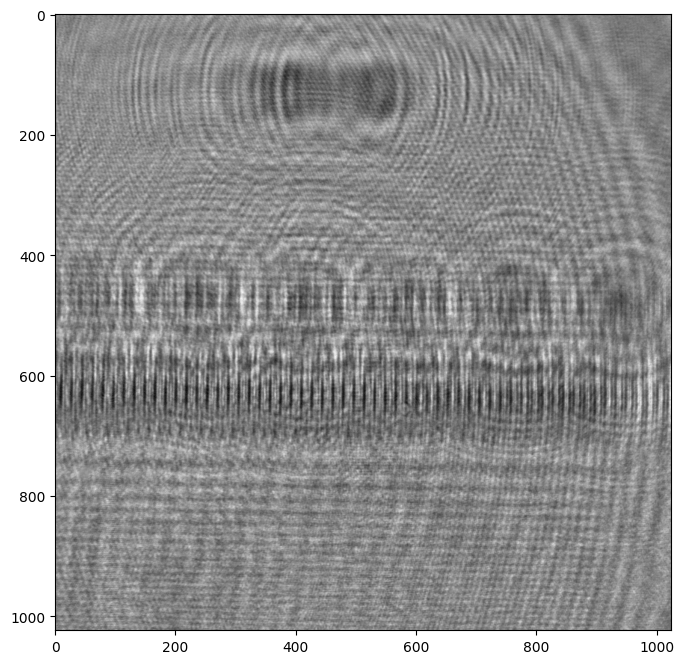

In [ ]:
I_recticle = plt.imread("./Lab3_Material/Reticle_LaHC.png")


plt.imshow(I_recticle, cmap="gray")
plt.show()

### 2.2 Comments on artifacts

The artifacts are a result of the edges in the image
We can remove them using zero or mean padding

### 2.3 CReconstruction without circular convolution artifacts

## 3. +++ Fresnel transform properties